# 04 - Resampling, Smoothing, Timezones and Final Output
**Goal:** finish the pipeline and save the cleaned dataset.

In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import cleaning as cl
RAW = "../data/raw/airline_passengers_dirty.csv"
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
clean = cl.clean_pipeline(RAW)
print(clean.isna().sum(), len(clean))

0 144


## Smoothing with a rolling mean

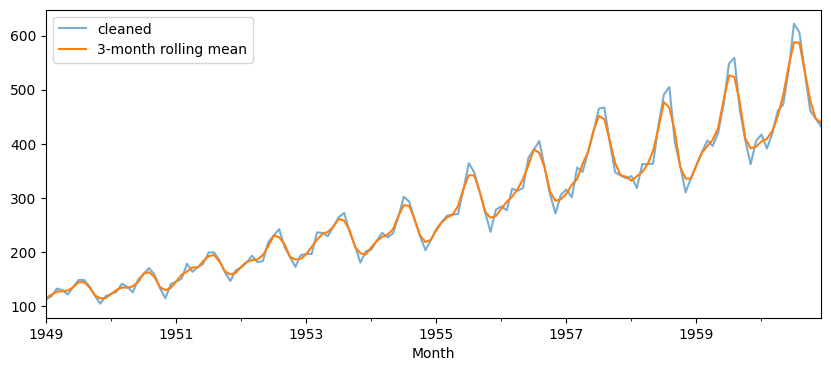

In [3]:
sm = cl.smooth(clean, 3)
clean.plot(label='cleaned', alpha=.6); sm.plot(label='3-month rolling mean')
plt.legend(); plt.show()

## Resampling to quarterly and yearly totals

Month
1949-01-01    362.0
1949-04-01    385.0
1949-07-01    432.0
1949-10-01    341.0
1950-01-01    389.0
Freq: QS-JAN, Name: Passengers, dtype: float64

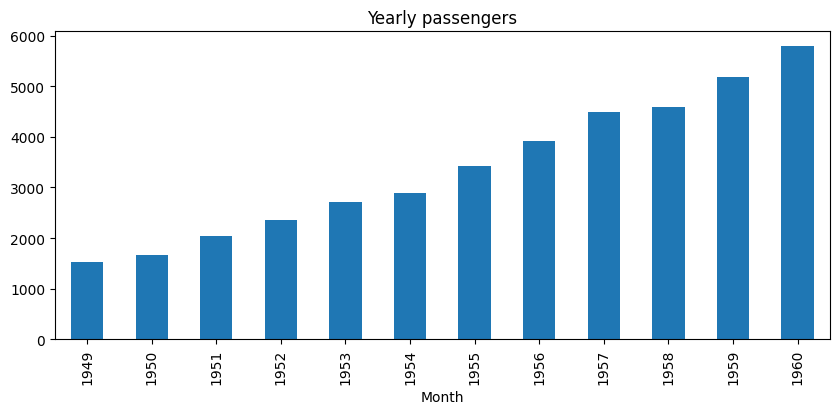

In [4]:
q = cl.resample_series(clean, 'QS', 'sum')
y = cl.resample_series(clean, 'YS', 'sum'); y.index = y.index.year
display(q.head()); y.plot(kind='bar', title='Yearly passengers'); plt.show()

## Timezone handling
Timestamps are timezone-naive. We localize to a zone, then convert to UTC.

In [5]:
tz = clean.copy()
tz.index = tz.index.tz_localize('Asia/Kolkata')
tz.head(3), tz.tz_convert('UTC').head(3)

(Month
 1949-01-01 00:00:00+05:30    112.0
 1949-02-01 00:00:00+05:30    118.0
 1949-03-01 00:00:00+05:30    132.0
 Name: Passengers, dtype: float64,
 Month
 1948-12-31 18:30:00+00:00    112.0
 1949-01-31 18:30:00+00:00    118.0
 1949-02-28 18:30:00+00:00    132.0
 Name: Passengers, dtype: float64)

## Save outputs
We save the cleaned data and a comparison figure used in the README.

Saved


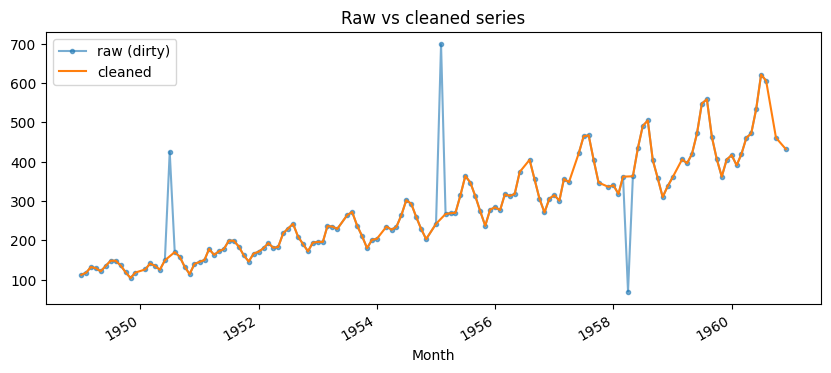

In [6]:
clean.rename('Passengers').to_csv('../data/cleaned/airline_passengers_clean.csv')
raw = pd.read_csv(RAW, parse_dates=['Month']).drop_duplicates('Month').set_index('Month').sort_index()['Passengers']
fig, ax = plt.subplots(figsize=(10, 4))
raw.plot(ax=ax, marker='.', alpha=.6, label='raw (dirty)'); clean.plot(ax=ax, label='cleaned')
ax.legend(); ax.set_title('Raw vs cleaned series')
fig.savefig('../images/cleaning_result.png', dpi=120, bbox_inches='tight')
print('Saved')